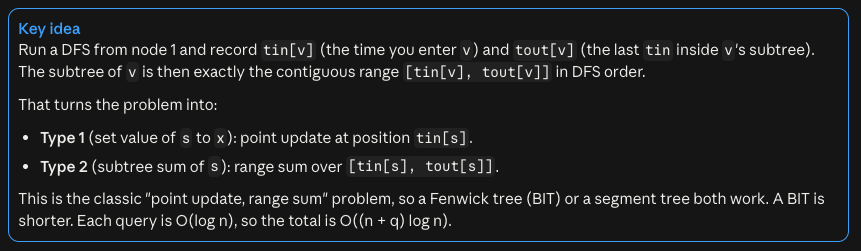

BIT holds values of nodes in dfs order

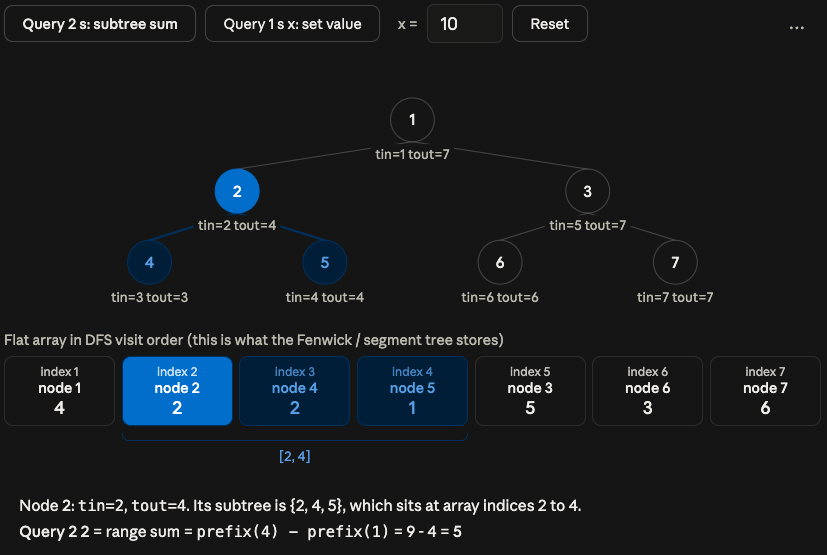


```cpp
  vll tin(N);
  vll tout(N);

  vll vis(N);
  vll order;
  ll counter = 0;
  auto dfs = [&](auto dfs, ll u) -> void
  {
    for (auto &next : G[u])
    {
      if (vis[next])
        continue;
      vis[next] = 1;
      order.pb(next);
      tin[next] = counter;
      tout[next] = counter;
      counter++;
      dfs(dfs, next);
    }
    tout[u] = counter - 1;
  };
  vis[0] = 1;
  tin[0] = counter;
  order.pb(0);
  counter++;
  dfs(dfs, 0);
```

Iterative dfs version:

```cpp
vll tin(N), tout(N), order;
order.reserve(N);
vector<int> parent(N, -1), it(N, 0), st;

st.push_back(0);
tin[0] = 0;
order.pb(0);

while (!st.empty())
{
  int u = st.back();
  if (it[u] < (int)G[u].size())
  {
    int v = G[u][it[u]++];
    if (v == parent[u])
      continue;
    parent[v] = u;
    tin[v] = order.size();
    order.pb(v);
    st.push_back(v);
  }
  else
  {
    tout[u] = (ll)order.size() - 1; // last index in u's subtree
    st.pop_back();
  }
}
```